# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [ ]:
ROLL_NO = 1024170172         # <-- your full roll number
NAME = "Aanya Garg"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [ ]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [ ]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [ ]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170172   Name: Aanya Garg   Fingerprint: 1A42A028   Tickets: 14

Ticket_ID                                                                                      Ticket_Text
      T01 I keep getting logged out of the laptop after resetting my password. I have tried several times!
      T02                     E-mail crashes while opening when connected to campus Wi-Fi. This is urgent.
      T03                                               The server stopped responding. Can you check this?
      T04                  Server is showing an error while uploading the file. I don't know what changed.
      T05                Printer is not working before the assignment deadline. I don't know what changed.
      T06                                                     The password failed to open. This is urgent.
      T07                                   The laptop keeps asking for login. I have tried several times!
      T08                                                The p

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [ ]:
import pandas as pd

rows = []

for _, row in df.iterrows():
    result = process_ticket(row["Ticket_Text"])

    rows.append({
        "Ticket_ID": row["Ticket_ID"],
        "Sentences": len(result["sentences"]),
        "Tokens": len(result["tokens"]),
        "Punctuation": len(result["punct"]),
        "Stopwords": len(result["stops"]),
        "Unique Tokens": len(set(result["tokens"])),
        "Final Tokens": len(result["final"])
    })

q1_table = pd.DataFrame(rows)

total_row = {
    "Ticket_ID": "TOTAL",
    "Sentences": q1_table["Sentences"].sum(),
    "Tokens": q1_table["Tokens"].sum(),
    "Punctuation": q1_table["Punctuation"].sum(),
    "Stopwords": q1_table["Stopwords"].sum(),
    "Unique Tokens": "-",
    "Final Tokens": q1_table["Final Tokens"].sum()
}

q1_table = pd.concat(
    [q1_table, pd.DataFrame([total_row])],
    ignore_index=True
)

display(q1_table)



,Ticket_ID,Sentences,Tokens,Punctuation,Stopwords,Unique Tokens,Final Tokens
0,T01,2,19,2,8,18,9
1,T02,2,14,2,5,13,7
2,T03,2,10,2,4,10,4
3,T04,2,17,2,7,16,8
4,T05,2,16,2,7,15,7
5,T06,2,10,2,4,9,4
6,T07,2,13,2,4,13,7
7,T08,2,11,2,5,11,4
8,T09,2,10,2,3,10,5
9,T10,1,5,1,0,5,4


In [ ]:

selected_text = df.iloc[0]["Ticket_Text"]
result = process_ticket(selected_text)

print("Selected ticket:", df.iloc[0]["Ticket_ID"])
print("Raw text:", selected_text)
print("Tokens:", result["tokens"])
print("Punctuation tokens:", result["punct"])
print("Stopwords:", result["stops"])
print("Final tokens:", result["final"])


Selected ticket: T01
Raw text: I keep getting logged out of the laptop after resetting my password. I have tried several times!
Tokens: ['i', 'keep', 'getting', 'logged', 'out', 'of', 'the', 'laptop', 'after', 'resetting', 'my', 'password', '.', 'i', 'have', 'tried', 'several', 'times', '!']
Punctuation tokens: ['.', '!']
Stopwords: ['i', 'out', 'of', 'the', 'after', 'my', 'i', 'have']
Final tokens: ['keep', 'getting', 'logged', 'laptop', 'resetting', 'password', 'tried', 'several', 'times']


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?


Words like isn't can get split into parts. Removing punctuation and stopwords doesn't always put them back together.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [ ]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]


import re

raw_tickets = df["Ticket_Text"].tolist()

long_words = [re.findall(r"\b[A-Za-z]{6,}\b", text) for text in raw_tickets]
number_pattern = r"\b\d+(?:\.\d+)*\b"
all_numbers = [re.findall(number_pattern, text) for text in raw_tickets]
capitalized_pattern = r"\b[A-Z][a-zA-Z]*\b"
capitalized_words = [re.findall(capitalized_pattern, text) for text in raw_tickets]
vowel_pattern = r"\b[aeiouAEIOU][a-zA-Z]*\b"
vowel_words = [re.findall(vowel_pattern, text) for text in raw_tickets]

print("Words longer than 5 letters:")
for ticket_id, words in zip(df["Ticket_ID"], long_words):
    print(ticket_id, words)

print("\nNumbers:")
for ticket_id, nums in zip(df["Ticket_ID"], all_numbers):
    print(ticket_id, nums)

print("\nCapitalized words:")
for ticket_id, words in zip(df["Ticket_ID"], capitalized_words):
    print(ticket_id, words)

print("\nWords starting with a vowel:")
for ticket_id, words in zip(df["Ticket_ID"], vowel_words):
    print(ticket_id, words)

email_pattern = r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"
url_pattern = r"https?://[^\s]+|www\.[^\s]+"
phone_pattern = r"(?<!\w)(?:\+?\d{1,3}[- ]?)?(?:\d{5}[- ]?\d{5}|\d{4}[- ]\d{3}[- ]\d{4})(?!\w)"

def clean_text(text):
    text = re.sub(email_pattern, "<EMAIL>", text)
    text = re.sub(url_pattern, "<URL>", text)
    text = re.sub(phone_pattern, "<PHONE>", text)
    return text

print("\nReplacements on raw tickets:")
for ticket_id, text in zip(df["Ticket_ID"], raw_tickets):
    print(ticket_id, ":", clean_text(text))

print("\nTesting TEST_LINES:")
for line in TEST_LINES:
    print("\nOriginal:", line)
    print("Long words:", re.findall(r"\b[A-Za-z]{6,}\b", line))
    print("Numbers:", re.findall(number_pattern, line))
    print("Capitalized words:", re.findall(capitalized_pattern, line))
    print("Vowel words:", re.findall(vowel_pattern, line))
    print("Cleaned:", clean_text(line))


Words longer than 5 letters:
T01 ['getting', 'logged', 'laptop', 'resetting', 'password', 'several']
T02 ['crashes', 'opening', 'connected', 'campus', 'urgent']
T03 ['server', 'stopped', 'responding']
T04 ['Server', 'showing', 'uploading', 'changed']
T05 ['Printer', 'working', 'before', 'assignment', 'deadline', 'changed']
T06 ['password', 'failed', 'urgent']
T07 ['laptop', 'asking', 'several']
T08 ['projector', 'failed']
T09 ['laptop', 'disconnecting', 'another', 'solution']
T10 ['appears']
T11 ['Password', 'working', 'yesterday', 'restarting', 'system', 'Please']
T12 []
T13 ['change', 'anything']
T14 ['helpdesk', 'thapar', 'thapar']

Numbers:
T01 []
T02 []
T03 []
T04 []
T05 []
T06 []
T07 []
T08 []
T09 []
T10 []
T11 []
T12 []
T13 []
T14 []

Capitalized words:
T01 ['I', 'I']
T02 ['E', 'Wi', 'Fi', 'This']
T03 ['The', 'Can']
T04 ['Server', 'I']
T05 ['Printer', 'I']
T06 ['The', 'This']
T07 ['The', 'I']
T08 ['The', 'Can']
T09 ['The', 'Is']
T10 ['Error']
T11 ['Password', 'Please']
T12 ['Is'

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

Words like “This,” “The,” “Server,” “Printer,” “Password,” “Error,” and “Write.” only because they start a sentence.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [ ]:

from nltk.tokenize import RegexpTokenizer, word_tokenize

pattern = r"https?://[^\s]+|www\.[^\s]+|[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}|\+?\d[\d -]{7,}\d|\d+(?:\.\d+)+|[A-Za-z]+(?:-[A-Za-z]+)*(?:'[A-Za-z]+)?|\d+"

tokenizer = RegexpTokenizer(pattern)

def my_tokenize(text):
    return tokenizer.tokenize(text)

for line in TEST_LINES:
    print("Original:", line)
    print("My tokens:", my_tokenize(line))
    print("Word tokens:", word_tokenize(line))
    print()

different = 0

for _, row in df.iterrows():
    text = row["Ticket_Text"]
    custom = my_tokenize(text)
    standard = word_tokenize(text)

    if custom != standard:
        different += 1

print("Tickets tokenized differently:", different)
print("Total tickets:", len(df))

for _, row in df.iterrows():
    text = row["Ticket_Text"]
    custom = my_tokenize(text)
    standard = word_tokenize(text)

    if custom != standard:
        print("\nTicket:", row["Ticket_ID"])
        print("Custom:", custom)
        print("Word tokenize:", standard)


Original: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
My tokens: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
Word tokens: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Original: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
My tokens: ['Call', '+91 98765 43210', '+91-98765-43210', 'or', '0175-239-3201', 'Version', '2.0.1', 'is', '95.5', 'done', 'fee', 'Rs', '1', '250']
Word tokens: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Original: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
My tokens: ['The', 'state-of-the-art',

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

All 14 tickets are tokenized differently by the two tokenizers. My custom tokenizer keeps contractions like “isn't” and phone numbers together, while `word_tokenize()` may split them into smaller tokens. They also handle punctuation differently.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [ ]:

import re
import pandas as pd
import nltk
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag

porter = PorterStemmer()
lancaster = LancasterStemmer()
regex_stemmer = RegexpStemmer(r"(ing|ed|es|s)$", min=3)
lemmatizer = WordNetLemmatizer()

def get_pos(tag):
    if tag.startswith("J"):
        return "a"
    elif tag.startswith("V"):
        return "v"
    elif tag.startswith("N"):
        return "n"
    elif tag.startswith("R"):
        return "r"
    return "n"

unique_tokens = sorted({
    token
    for text in df["Ticket_Text"]
    for token in process_ticket(text)["final"]
})

tagged_words = pos_tag(unique_tokens)

rows = []

for word, tag in tagged_words:
    p = porter.stem(word)
    l = lancaster.stem(word)
    r = regex_stemmer.stem(word)
    lemma = lemmatizer.lemmatize(word, get_pos(tag))

    if len({p, l, r, lemma}) > 1:
        rows.append({
            "Word": word,
            "Porter": p,
            "Lancaster": l,
            "Regexp": r,
            "WordNet Lemma": lemma
        })

result_table = pd.DataFrame(rows)
display(result_table)
print("Number of words with differing outputs:", len(result_table))


,Word,Porter,Lancaster,Regexp,WordNet Lemma
0,another,anoth,anoth,another,another
1,anything,anyth,anyth,anyth,anything
2,assignment,assign,assign,assignment,assignment
3,campus,campu,camp,campu,campus
4,change,chang,chang,change,change
5,changed,chang,chang,chang,change
6,code,code,cod,code,code
7,deadline,deadlin,deadlin,deadline,deadline
8,error,error,er,error,error
9,file,file,fil,file,file


Number of words with differing outputs: 30


**Observe:** Give one over-stemming and one under-stemming example from your table.

Over-stemming: “error” → “er” using Lancaster Stemmer. Too much of the word is removed.

Under-stemming: “changed” → “change” using Regexp Stemmer, while “changing” would remain “changing” with this pattern. Related forms are not reduced to the same stem.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

S1
Total tokens: 167
Unique tokens: 92
TTR: 0.5509

S2
Total tokens: 140
Unique tokens: 87
TTR: 0.6214

S3
Total tokens: 81
Unique tokens: 60
TTR: 0.7407

S4
Total tokens: 81
Unique tokens: 57
TTR: 0.7037

Top 10 words in S1:


,Word,Frequency
0,.,18
1,the,9
2,i,7
3,is,6
4,?,5
5,to,4
6,this,4
7,n't,4
8,laptop,3
9,password,3


Top 10 words in S3:


,Word,Frequency
0,n't,4
1,laptop,3
2,password,3
3,tried,2
4,several,2
5,times,2
6,urgent,2
7,server,2
8,check,2
9,error,2


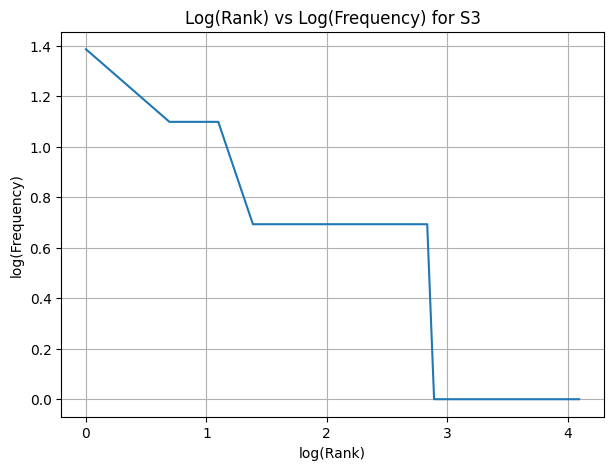

Top 5 bigrams in S1:
[(('.', 'i'), 4), (('the', 'laptop'), 3), (('.', 'the'), 3), (('i', 'have'), 2), (('have', 'tried'), 2)]

Top 5 bigrams in S3:
[(('tried', 'several'), 2), (('several', 'times'), 2), (("n't", 'know'), 2), (('know', 'changed'), 2), (('failed', 'open'), 2)]


In [ ]:

from collections import Counter
from nltk.stem import PorterStemmer
import matplotlib.pyplot as plt
import math
import pandas as pd

porter = PorterStemmer()

S1 = []
S2 = []
S3 = []

for text in df["Ticket_Text"]:
    result = process_ticket(text)
    S1.extend(result["tokens"])
    S2.extend([t for t in result["tokens"] if not all(c in ".,!?;:'\"()[]{}-" for c in t)])
    S3.extend(result["final"])

S4 = [porter.stem(t) for t in S3]

sets = {"S1": S1, "S2": S2, "S3": S3, "S4": S4}

for name, tokens in sets.items():
    total = len(tokens)
    unique = len(set(tokens))
    ttr = unique / total if total else 0
    print(name)
    print("Total tokens:", total)
    print("Unique tokens:", unique)
    print("TTR:", round(ttr, 4))
    print()

freq1 = Counter(S1)
freq3 = Counter(S3)

print("Top 10 words in S1:")
display(pd.DataFrame(freq1.most_common(10), columns=["Word", "Frequency"]))

print("Top 10 words in S3:")
display(pd.DataFrame(freq3.most_common(10), columns=["Word", "Frequency"]))

rank_freq = sorted(freq3.values(), reverse=True)
ranks = range(1, len(rank_freq) + 1)

plt.figure(figsize=(7, 5))
plt.plot([math.log(r) for r in ranks],
         [math.log(f) for f in rank_freq])
plt.xlabel("log(Rank)")
plt.ylabel("log(Frequency)")
plt.title("Log(Rank) vs Log(Frequency) for S3")
plt.grid(True)
plt.show()

print("Top 5 bigrams in S1:")
print(Counter(zip(S1, S1[1:])).most_common(5))

print("\nTop 5 bigrams in S3:")
print(Counter(zip(S3, S3[1:])).most_common(5))


**Observe:** Why does TTR change from S1 to S4 in your data?

Actually, it increases because punctuation and stopwords are removed, and stemming combines related words. In my data, TTR increases from 0.5509 (S1) to 0.7037 (S4), as the total number of tokens decreases more than the number of unique tokens.